<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/01_repasses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/01_repasses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resultado final, notebook 01: repasses obrigatórios do Estado aos municípios do RN

**Membros:** Brenda Gomes, Fernanda Nascimento, Gabriel Borges e Renata Nascimento

**Tema:** Para onde vai o dinheiro do Estado nos municípios do RN?

**Objetivo:** montar a base de **quanto cada município recebeu de repasses obrigatórios** do Governo do RN de 2020 a
2023, junto com os dados de apoio (população, PIB e CadÚnico), e salvar em CSV para a junção do notebook 04.

Este notebook reaproveita o código do `notebooks/01_coleta.ipynb` (CP1), com a mesma lógica e os mesmos resultados.
A diferença é que tudo o que ele gera fica dentro de `resultado_final/`, no padrão dos outros notebooks desta pasta.

**O que são os repasses obrigatórios:** o Estado divide com os municípios uma parte dos impostos que arrecada. As
regras estão na Constituição e em lei estadual, e levam em conta principalmente a atividade econômica de cada município.

| Repasse | Parte que vai para os municípios |
|---|---|
| ICMS (cota-parte) | 25% do ICMS arrecadado |
| IPVA | 50% do IPVA dos veículos registrados no município |
| IPI-Exportação | 25% do que o Estado recebe da União |
| Royalties do petróleo | 25% do que o Estado recebe |

**Fontes (ligadas pelo código IBGE do município):**

| Fonte | O que traz | Como coletamos |
|---|---|---|
| SEFAZ/RN | Repasses mensais por município | Planilhas `.xls` (uma por ano), guardadas em `dados/sefaz` |
| IBGE | Municípios e regiões, população (Censo 2022), PIB municipal e IPCA | API, com cópia em `dados/ibge` |
| MDS, CadÚnico | Famílias e pessoas cadastradas e de baixa renda (dezembro) | API, com cópia em `dados/cadunico` |

**Decisões (as mesmas do notebook 01 do CP1):**
- **Período de 2020 a 2023:** é o maior intervalo em que todas as fontes têm dado. O PIB municipal só vai até 2023.
- **População fixa no Censo 2022** para todos os anos. As estimativas anteriores ficaram cerca de 7% acima do Censo, e
  2023 não tem população publicada. Com a população fixa, a variação por habitante reflete só a variação do dinheiro.
- **Valores em reais de 2023**, corrigidos pela média anual do IPCA. O IPCA subiu cerca de 24% entre 2020 e 2023.

**Arquivos gerados (pasta `resultado_final/saida/`):**

| Arquivo | Conteúdo |
|---|---|
| `01_repasses_municipio_ano.csv` | Uma linha por município, ano e tipo de repasse |
| `01_repasses_municipios_2020_2023.csv` | Uma linha por município: somas de 2020 a 2023 e valores por habitante. **Vai para a junção do notebook 04** |
| `01_base_municipios_2020_2023.csv` | Uma linha por município e ano: repasses, população, PIB e CadÚnico. É a mesma base do CP1, usada nas análises |

## 1. Bibliotecas e funções

In [1]:
import os
import re
import time
import glob
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import requests

ANOS = [2020, 2021, 2022, 2023]
ANO_PRECOS = 2023
REPO = 'Renata-Nascimento/Projeto-U02-CD'
RAW_GITHUB = f'https://raw.githubusercontent.com/{REPO}/main/'
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')

AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
CINZA, CINZA_CLARO = '#a3a29b', '#d6d5d0'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'legend.frameon': True,
})

def reais(x, _=None):
    """Formata em reais: 1500 -> 'R$ 1,5 mil' | 2_300_000 -> 'R$ 2,3 mi'."""
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if abs(x) >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.2f}'.rstrip('0').rstrip('.').replace('.', ',')
            return f'R$ {texto}{sufixo}'
    return f'R$ {x:.0f}'

def virgula(x, casas=1):
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

FORMATO_REAIS = mticker.FuncFormatter(reais)

def ler_csv(caminho, tentativas=3, **kwargs):
    """Lê do GitHub do projeto (tenta de novo se a conexão cair); se não conseguir, lê a cópia local (mesmo caminho)."""
    for _ in range(tentativas):
        try:
            return pd.read_csv(RAW_GITHUB + caminho, **kwargs)
        except Exception as e:
            erro = e
            if '404' in str(e):
                break
            time.sleep(3)
    if os.path.exists(caminho):
        return pd.read_csv(caminho, **kwargs)
    if '404' in str(erro):
        raise FileNotFoundError(
            f'O arquivo "{caminho}" não está no GitHub do projeto. '
            f'Suba-o para a pasta {os.path.dirname(caminho)}/ do repositório, com o mesmo nome, '
            'e rode a célula de novo.') from None
    raise ConnectionError(
        f'Não consegui baixar "{caminho}" do GitHub: o ambiente parece estar sem internet. '
        f'Erro original: {erro}') from None

os.makedirs('resultado_final/saida', exist_ok=True)

# Cidades em destaque, encontradas no notebook 06: recebem muito mais repasses por habitante do que as demais,
# por concentrarem parques eólicos e a produção de petróleo. Aqui servem só para marcar nos gráficos;
# a lista final sai do notebook 04, depois de juntar repasses, convênios e emendas.
CIDADES_DESTAQUE = ['Guamaré', 'São Bento do Norte', 'Pedra Grande', 'Parazinho', 'Galinhos', 'Bodó', 'Serra do Mel']

## 2. Lista oficial de municípios (IBGE)

É a "régua" do projeto: todo nome de município das outras fontes é convertido para o código IBGE.

**Plano B (vale para todas as APIs):** o Colab roda fora do Brasil, e as APIs do governo às vezes não respondem. Nesse
caso, o código lê a cópia guardada na pasta `dados/` do repositório.

In [2]:
try:
    resp = requests.get('https://servicodados.ibge.gov.br/api/v1/localidades/estados/24/municipios', timeout=60)
    resp.raise_for_status()
    municipios = pd.DataFrame([{
        'cod_ibge': m['id'],
        'municipio': m['nome'],
        'mesorregiao': m['microrregiao']['mesorregiao']['nome'],
        'regiao_intermediaria': m['regiao-imediata']['regiao-intermediaria']['nome'],
    } for m in resp.json()])
    print('Municípios lidos da API do IBGE')
except (requests.exceptions.RequestException, ValueError) as erro:
    print(f'API do IBGE não respondeu ({erro.__class__.__name__}); usando a cópia do GitHub')
    municipios = ler_csv('dados/ibge/municipios_rn.csv')[['cod_ibge', 'municipio', 'mesorregiao', 'regiao_intermediaria']]

assert len(municipios) == 167
municipios.head()

API do IBGE não respondeu (ConnectTimeout); usando a cópia do GitHub


,cod_ibge,municipio,mesorregiao,regiao_intermediaria
0,2400109,Acari,Central Potiguar,Caicó
1,2400208,Assú,Oeste Potiguar,Mossoró
2,2400307,Afonso Bezerra,Central Potiguar,Mossoró
3,2400406,Água Nova,Oeste Potiguar,Mossoró
4,2400505,Alexandria,Oeste Potiguar,Mossoró


### Padronização dos nomes

As planilhas da SEFAZ não têm código IBGE, só o nome, e escrevem o mesmo município de jeitos diferentes
(`SEN ELOI DE SOUZA` × `SENADOR ELOI DE SOUZA`, `LAGOA D'ANTA` × `LAGOA DANTA`). Por isso criamos uma **chave** (só
letras, sem acento e sem espaço) e um **de-para** para nomes abreviados ou antigos.

In [3]:
def chave(nome):
    """'Olho d'Água do Borges' -> 'OLHODAGUADOBORGES'"""
    s = unicodedata.normalize('NFKD', str(nome)).encode('ascii', 'ignore').decode().upper()
    return re.sub(r'[^A-Z]', '', s)

DE_PARA = {
    'ARES': 'AREZ',
    'BOASAUDE': 'JANUARIOCICCO',                 # nome popular (oficial: Januário Cicco)
    'CAICARADORIODOSVENTOS': 'CAICARADORIODOVENTO',
    'GOVDIXSEPTROSADO': 'GOVERNADORDIXSEPTROSADO',
    'IPANGUASSU': 'IPANGUACU',
    'OLHODAGUADOSBORGES': 'OLHODAGUADOBORGES',
    'RUIBARBOSA': 'RUYBARBOSA',
    'SAOMIGUELDETOUROS': 'SAOMIGUELDOGOSTOSO',   # nome antigo
    'SENELOIDESOUZA': 'SENADORELOIDESOUZA',
    'SENGEORGINOAVELINO': 'SENADORGEORGINOAVELINO',
}

COD_POR_CHAVE = dict(zip(municipios['municipio'].map(chave), municipios['cod_ibge']))
assert len(COD_POR_CHAVE) == 167

## 3. Repasses obrigatórios (SEFAZ/RN)

**Fonte:** site da SEFAZ/RN → Transparência → Transferências para os Municípios do RN. As planilhas `.xls` (uma por
ano) estão guardadas na pasta `dados/sefaz` do repositório. A célula abaixo pergunta ao GitHub quais arquivos existem
nessa pasta e baixa cada um para o Colab, sem precisar de upload manual.

In [4]:
PASTA_SEFAZ = 'dados/sefaz'
os.makedirs(PASTA_SEFAZ, exist_ok=True)

try:
    resposta = requests.get(f'https://api.github.com/repos/{REPO}/contents/{PASTA_SEFAZ}', timeout=60)
    resposta.raise_for_status()
    for item in resposta.json():
        destino = os.path.join(PASTA_SEFAZ, item['name'])
        if item['name'].lower().endswith('.xls') and not os.path.exists(destino):   # não baixa de novo na mesma sessão
            with open(destino, 'wb') as f:
                f.write(requests.get(item['download_url'], timeout=120).content)
except requests.exceptions.RequestException as erro:
    print(f'Não consegui listar a pasta no GitHub ({erro.__class__.__name__}); usando os arquivos que já estão aqui')

arquivos = sorted(glob.glob(f'{PASTA_SEFAZ}/*.xls'))
if not arquivos:
    raise FileNotFoundError(f'Nenhuma planilha .xls encontrada em {REPO}/{PASTA_SEFAZ}')
print(len(arquivos), 'planilhas:', ', '.join(os.path.basename(a) for a in arquivos))

7 planilhas: repasses_2019.xls, repasses_2020.xls, repasses_2021.xls, repasses_2022.xls, repasses_2023.xls, repasses_2024.xls, repasses_2025.xls


### Como é o arquivo bruto

É um relatório feito para impressão: linhas de cabeçalho, municípios nas linhas, meses nas colunas, linha de TOTAL e
rodapé com observações. Cada planilha tem uma aba por repasse (ICMS, IPVA, IPI e ROYALTIES).

In [5]:
pd.read_excel(arquivos[0], sheet_name='ICMS', header=None).iloc[6:14, :5]

,0,1,2,3,4
6,NaN,NaN,NaN,NaN,NaN
7,NaN,ÍNDICE %,ÍNDICE %,2 0 1 8 ( *** ),2 0 1 9
8,MUNICÍPIOS,2018,2019,JANEIRO,JANEIRO
9,NaN,NaN,NaN,NaN,"134,614,167.0"
10,ACARI,0.2,0.2,NaN,"300,728.0"
11,AFONSO BEZERRA,0.2,0.2,NaN,"268,824.5"
12,AGUA NOVA,0.1,0.1,NaN,"143,633.3"
13,ALEXANDRIA,0.2,0.2,NaN,"254,420.8"


### Leitura de todas as planilhas

O layout muda de um ano para outro (colunas extras, mês repetido, TOTAL em posições diferentes). Por isso:
1. achamos a linha de cabeçalho pela palavra `MUNICÍPIOS`;
2. achamos as colunas pelo **nome do mês**. Na aba ICMS de 2021 a 2023 existe uma coluna a mais,
   `INDICE <ano anterior> JANEIRO` (parcela de janeiro paga pelo índice do ano anterior). Ela também é dinheiro
   repassado no ano, então contamos toda coluna cujo nome **termina** com um mês. Sem ela, o ICMS ficaria de 1% a 2%
   abaixo do valor real;
3. ficamos só com as linhas cujo nome bate com a lista do IBGE (isso descarta totais e rodapés);
4. paramos na linha TOTAL que vem depois dos municípios.

In [6]:
MESES = ['JANEIRO', 'FEVEREIRO', 'MARCO', 'ABRIL', 'MAIO', 'JUNHO',
         'JULHO', 'AGOSTO', 'SETEMBRO', 'OUTUBRO', 'NOVEMBRO', 'DEZEMBRO']

def eh_mes(texto_coluna):
    """'JANEIRO' -> True; 'INDICEJANEIRO' (coluna 'INDICE 2020 JANEIRO') -> True; 'TOTAL' -> False."""
    return any(texto_coluna.endswith(m) for m in MESES)

def ler_aba(arquivo, aba, ano):
    bruto = pd.read_excel(arquivo, sheet_name=aba, header=None)
    lin_cab = bruto.index[bruto[0].astype(str).str.upper().str.startswith('MUNIC')][0]
    cabecalho = [chave(c) for c in bruto.iloc[lin_cab]]
    corpo = bruto.iloc[lin_cab + 1:]

    k = corpo[0].map(chave).replace(DE_PARA)
    inicio = k[k.isin(list(COD_POR_CHAVE))].index[0]
    fim = corpo.index[(corpo.index > inicio) & corpo[0].astype(str).str.upper().str.contains('TOTA')]
    if len(fim):
        corpo, k = corpo.loc[:fim[0] - 1], k.loc[:fim[0] - 1]
    corpo = corpo.assign(cod_ibge=k.map(COD_POR_CHAVE)).dropna(subset=['cod_ibge'])

    colunas_meses = [j for j, c in enumerate(cabecalho) if eh_mes(c)]
    valores = corpo[colunas_meses].apply(pd.to_numeric, errors='coerce')
    return pd.DataFrame({'cod_ibge': corpo['cod_ibge'].astype(int).values,
                         'ano': ano, 'tipo': aba,
                         'valor': valores.sum(axis=1).values})

partes = []
for arq in arquivos:
    ano = int(re.search(r'(20\d{2})', os.path.basename(arq)).group(1))
    if ano in ANOS:
        for aba in ['ICMS', 'IPVA', 'IPI', 'ROYALTIES']:
            partes.append(ler_aba(arq, aba, ano))
repasses = pd.concat(partes, ignore_index=True)

# Conferência: cada ano e tipo deve ter os 167 municípios, sem repetição
assert (repasses.groupby(['ano', 'tipo'])['cod_ibge'].nunique() == 167).all(), 'faltou município em alguma aba'
assert not repasses.duplicated(['cod_ibge', 'ano', 'tipo']).any(), 'município repetido'
print('OK: 167 municípios em cada ano e tipo de repasse')

# Total repassado por ano (R$ milhões, sem correção)
(repasses.pivot_table(index='ano', columns='tipo', values='valor', aggfunc='sum') / 1e6).round(1)

OK: 167 municípios em cada ano e tipo de repasse


tipo,ICMS,IPI,IPVA,ROYALTIES
ano,,,,
2020,"1,414.5",1.5,197.8,20.2
2021,"1,669.5",1.6,219.0,35.5
2022,"1,766.0",2.2,250.0,52.0
2023,"2,100.2",4.3,307.0,41.7


## 4. IBGE: população, PIB e inflação

- **População:** Censo 2022 (tabela SIDRA 4709), fixa para todos os anos.
- **PIB municipal** 2020–2023 (tabela 5938), em mil reais, sem correção.
- **IPCA** (tabela 1737): número-índice mensal. O fator de cada ano é **média do IPCA de 2023 ÷ média do IPCA do ano**:
  multiplicando um valor do ano por esse fator, ele fica em reais de 2023.

In [7]:
def sidra(caminho):
    dados = requests.get('https://apisidra.ibge.gov.br/values' + caminho, timeout=120).json()
    return pd.DataFrame(dados[1:])

try:
    populacao = sidra('/t/4709/n6/in%20n3%2024/v/93/p/2022')[['D1C', 'V']]
    populacao.columns = ['cod_ibge', 'populacao']
    pib = sidra('/t/5938/n6/in%20n3%2024/v/37/p/' + ','.join(map(str, ANOS)))[['D1C', 'D3N', 'V']]
    pib.columns = ['cod_ibge', 'ano', 'pib_mil_reais']
    print('População e PIB lidos da API SIDRA')
except (requests.exceptions.RequestException, ValueError) as erro:
    print(f'API SIDRA não respondeu ({erro.__class__.__name__}); usando a cópia do GitHub')
    pop_copia = ler_csv('dados/ibge/populacao_rn.csv')
    populacao = pop_copia.loc[pop_copia['ano'] == 2022, ['cod_ibge', 'populacao']]   # Censo 2022
    pib = ler_csv('dados/ibge/pib_rn.csv')
    pib = pib[pib['ano'].isin(ANOS)]

populacao = populacao.astype({'cod_ibge': int, 'populacao': int})
pib = pib.astype({'cod_ibge': int, 'ano': int, 'pib_mil_reais': float})
assert len(populacao) == 167 and pib.groupby('ano')['cod_ibge'].nunique().eq(167).all()

try:
    ipca = sidra(f'/t/1737/n1/all/v/2266/p/{ANOS[0]}01-{ANO_PRECOS}12')[['D3C', 'V']]
    print('IPCA lido da API SIDRA')
except (requests.exceptions.RequestException, ValueError) as erro:
    print(f'API SIDRA não respondeu ({erro.__class__.__name__}); usando a cópia do GitHub')
    ipca = ler_csv('dados/ibge/ipca_mensal.csv', dtype={'anomes': str})
    ipca.columns = ['D3C', 'V']
ipca['ano'] = ipca['D3C'].str[:4].astype(int)
ipca['V'] = ipca['V'].astype(float)
ipca = ipca[ipca['ano'].between(ANOS[0], ANO_PRECOS)].groupby('ano')['V'].mean()

fator_2023 = (ipca[ANO_PRECOS] / ipca).rename('fator_ipca').reset_index()
fator_2023

População e PIB lidos da API SIDRA
IPCA lido da API SIDRA


,ano,fator_ipca
0,2020,1.2
1,2021,1.1
2,2022,1.0
3,2023,1.0


## 5. CadÚnico (MDS)

API pública do MDS (MI Social), posição de **dezembro** de cada ano. O MDS usa o código IBGE com **6 dígitos** (sem
o último dígito verificador).

O endereço antigo da API (`aplicacoes.mds.gov.br/sagi/servicos/misocial`) saiu do ar em 21/10/2026. Os mesmos dados
voltaram em `dadosabertos.mds.gov.br/misocial/`, o endereço usado pelo
[conjunto de dados do CadÚnico no dados.gov.br](https://dados.gov.br/dados/conjuntos-dados/familias-por-faixa-de-renda-com-cadastro-atualizado-no-cadastro-unico).
Se a API não responder, usamos a cópia `dados/cadunico/cadunico_dezembro_rn.csv` (dezembro de 2012 a 2025).

In [8]:
CAMPOS_CADUNICO = {
    'codigo_ibge': 'cod_ibge6',
    'anomes_s': 'anomes',
    'cadun_qtd_familias_cadastradas_i': 'cad_familias',
    'cadun_qtd_pessoas_cadastradas_i': 'cad_pessoas',
    'cadun_qtd_pessoas_cadastradas_rfpc_ate_meio_sm_i': 'cad_baixa_renda',
}
params = {
    'q': '*:*',
    'fq': ['sigla_uf:RN', 'anomes_s:(' + ' OR '.join(f'{a}12' for a in ANOS) + ')'],
    'fl': ','.join(CAMPOS_CADUNICO), 'rows': 2000, 'wt': 'json',
}
try:
    r = requests.get('https://dadosabertos.mds.gov.br/misocial/', params=params, timeout=(20, 120))
    r.raise_for_status()
    cadunico = pd.DataFrame(r.json()['response']['docs']).rename(columns=CAMPOS_CADUNICO)
    cadunico['ano'] = cadunico['anomes'].astype(str).str[:4].astype(int)
    cadunico = cadunico.drop(columns='anomes')
    print('CadÚnico lido da API do MDS')
except (requests.exceptions.RequestException, ValueError, KeyError) as erro:
    print(f'API do MDS não respondeu ({erro.__class__.__name__}); usando a cópia do GitHub')
    cadunico = ler_csv('dados/cadunico/cadunico_dezembro_rn.csv')
    cadunico = cadunico[cadunico['ano'].isin(ANOS)]

cadunico = cadunico.astype({'cod_ibge6': int, 'ano': int, 'cad_familias': int, 'cad_pessoas': int, 'cad_baixa_renda': int})
assert cadunico.groupby('ano')['cod_ibge6'].nunique().eq(167).all()
cadunico.groupby('ano')[['cad_familias', 'cad_pessoas', 'cad_baixa_renda']].sum()

CadÚnico lido da API do MDS


,cad_familias,cad_pessoas,cad_baixa_renda
ano,,,
2020,643272,1717404,1524281
2021,713381,1830511,1621902
2022,884886,2027757,1786640
2023,921637,2078471,1661628


## 6. Integração: uma linha por município e ano (167 × 4 = 668 linhas)

In [9]:
rep_anual = (repasses
             .pivot_table(index=['cod_ibge', 'ano'], columns='tipo', values='valor', aggfunc='sum')
             .rename(columns=str.lower).add_prefix('rep_').reset_index())
rep_anual.columns.name = None
rep_anual['rep_total'] = rep_anual[['rep_icms', 'rep_ipva', 'rep_ipi', 'rep_royalties']].sum(axis=1)

base = (municipios
        .merge(pd.DataFrame({'ano': ANOS}), how='cross')        # todas as combinações município × ano
        .merge(rep_anual, on=['cod_ibge', 'ano'], how='left')
        .merge(populacao, on='cod_ibge', how='left')            # Censo 2022 para todos os anos
        .merge(pib, on=['cod_ibge', 'ano'], how='left')
        .merge(fator_2023, on='ano', how='left')
        .assign(cod_ibge6=lambda d: d['cod_ibge'] // 10)
        .merge(cadunico, on=['cod_ibge6', 'ano'], how='left')
        .drop(columns='cod_ibge6'))

# Valores em R$ de 2023
base['rep_total_real'] = base['rep_total'] * base['fator_ipca']
base['pib_real_mil'] = base['pib_mil_reais'] * base['fator_ipca']

# Variáveis por habitante
base['rep_per_capita'] = base['rep_total_real'] / base['populacao']
base['pib_per_capita'] = base['pib_real_mil'] * 1000 / base['populacao']
base['pct_baixa_renda'] = base['cad_baixa_renda'] / base['populacao'] * 100
base['porte'] = pd.cut(base['populacao'], bins=[0, 5_000, 10_000, 20_000, 50_000, np.inf],
                       labels=['até 5 mil', '5–10 mil', '10–20 mil', '20–50 mil', 'mais de 50 mil'])

print(base.shape)
base.head()

(668, 22)


,cod_ibge,municipio,mesorregiao,regiao_intermediaria,ano,rep_icms,rep_ipi,rep_ipva,rep_royalties,rep_total,...,fator_ipca,cad_baixa_renda,cad_familias,cad_pessoas,rep_total_real,pib_real_mil,rep_per_capita,pib_per_capita,pct_baixa_renda,porte
0,2400109,Acari,Central Potiguar,Caicó,2020,"3,116,225.1","3,279.7","385,048.8","44,590.6","3,549,144.1",...,1.2,5656,2574,6675,"4,393,441.2","163,709.4",414.6,"15,448.7",53.4,10–20 mil
1,2400109,Acari,Central Potiguar,Caicó,2021,"3,648,453.7","3,571.7","422,640.5","77,605.3","4,152,271.1",...,1.1,5851,2771,6940,"4,746,044.1","162,296.8",447.9,"15,315.4",55.2,10–20 mil
2,2400109,Acari,Central Potiguar,Caicó,2022,"3,979,197.7","4,877.0","491,858.1","113,601.8","4,589,534.5",...,1.0,6052,3077,7262,"4,800,357.6","181,679.0",453.0,"17,144.4",57.1,10–20 mil
3,2400109,Acari,Central Potiguar,Caicó,2023,"4,872,919.3","9,948.1","586,816.7","96,841.4","5,566,525.6",...,1.0,5048,3017,7041,"5,566,525.6","195,828.0",525.3,"18,479.6",47.6,10–20 mil
4,2400208,Assú,Oeste Potiguar,Mossoró,2020,"19,394,717.3","20,412.2","2,109,941.9","277,522.0","21,802,593.4",...,1.2,30759,12265,34268,"26,989,157.8","1,447,573.3",477.7,"25,622.6",54.4,mais de 50 mil


## 7. Qualidade dos dados

In [10]:
print('Linhas:', len(base), '(esperado 167 × 4 =', 167 * len(ANOS), ')')
print('Valores faltando:', base.isna().sum().sum())
print('Pares município-ano repetidos:', base.duplicated(['cod_ibge', 'ano']).sum())
assert len(base) == 668 and base.isna().sum().sum() == 0 and not base.duplicated(['cod_ibge', 'ano']).any()

# Municípios com mais pessoas no CadÚnico do que habitantes (cadastro desatualizado ou população subestimada)
acima = base[base['cad_pessoas'] > base['populacao']]
print(f'\n{len(acima)} casos, em {acima["municipio"].nunique()} municípios, com mais pessoas no CadÚnico do que habitantes:')
acima.pivot_table(index='municipio', columns='ano', values='cad_pessoas', aggfunc='sum')

Linhas: 668 (esperado 167 × 4 = 668 )
Valores faltando: 0
Pares município-ano repetidos: 0

31 casos, em 12 municípios, com mais pessoas no CadÚnico do que habitantes:


ano,2020,2021,2022,2023
municipio,,,,
Bodó,"2,601.0","2,704.0","2,804.0","2,843.0"
Caiçara do Rio do Vento,NaN,NaN,"3,310.0",NaN
Japi,"5,652.0","5,876.0","6,050.0","5,867.0"
João Dias,NaN,NaN,"2,166.0","2,171.0"
Lagoa Salgada,NaN,NaN,"9,236.0","9,688.0"
Lagoa de Velhos,NaN,"2,595.0","2,624.0",NaN
Monte das Gameleiras,"2,416.0","2,540.0","2,636.0","2,645.0"
Paraná,NaN,NaN,NaN,"3,976.0"
Severiano Melo,NaN,NaN,"5,659.0","5,718.0"


In [11]:
# Efeito da correção pela inflação no total do estado (R$ milhões)
efeito = base.groupby('ano')[['rep_total', 'rep_total_real']].sum() / 1e6
efeito['crescimento_sem_correcao_%'] = (efeito['rep_total'] / efeito['rep_total'].iloc[0] - 1) * 100
efeito['crescimento_real_%'] = (efeito['rep_total_real'] / efeito['rep_total_real'].iloc[0] - 1) * 100
efeito.rename(columns={'rep_total': 'Total sem correção (R$ mi)', 'rep_total_real': 'Total em R$ de 2023 (R$ mi)'}).round(1)

,Total sem correção (R$ mi),Total em R$ de 2023 (R$ mi),crescimento_sem_correcao_%,crescimento_real_%
ano,,,,
2020,"1,634.1","2,022.8",0.0,0.0
2021,"1,925.6","2,201.0",17.8,8.8
2022,"2,070.2","2,165.3",26.7,7.0
2023,"2,453.2","2,453.2",50.1,21.3


**Leitura:** sem a correção pela inflação, os repasses parecem crescer bem mais do que cresceram de fato. Por isso,
daqui em diante, todos os valores estão em reais de 2023.

## 8. Visão geral

### 8.1 Por ano e tipo de repasse

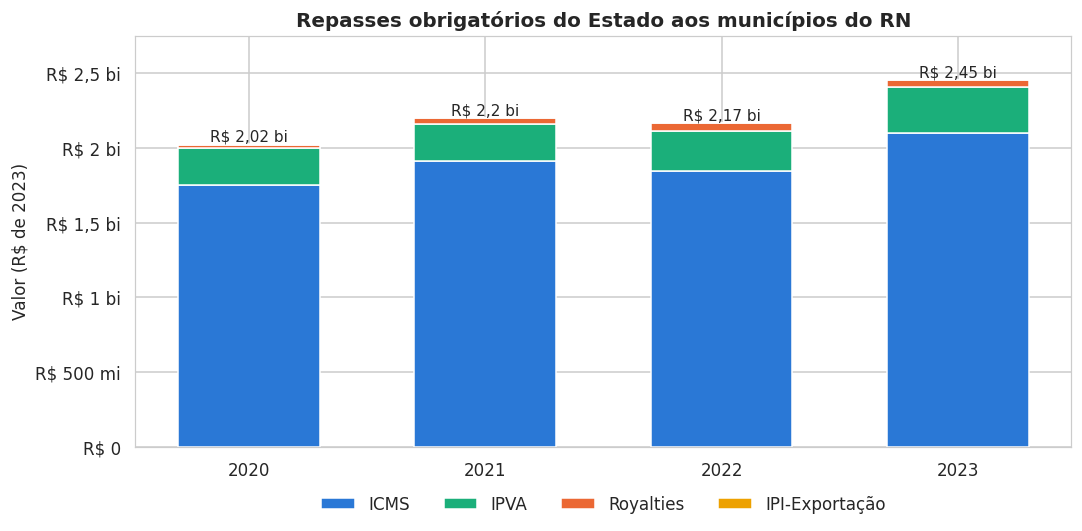

Participação de cada repasse em 2020–2023: ICMS 86,0% | IPVA 12,0% | Royalties 1,8% | IPI-Exportação 0,1%


tipo,ICMS,IPI,IPVA,ROYALTIES
ano,,,,
2020,"1,751.0",1.8,244.9,25.1
2021,"1,908.2",1.9,250.3,40.6
2022,"1,847.1",2.3,261.5,54.4
2023,"2,100.2",4.3,307.0,41.7


In [12]:
repasses = repasses.merge(fator_2023, on='ano')
repasses['valor_real'] = repasses['valor'] * repasses['fator_ipca']
por_ano = repasses.pivot_table(index='ano', columns='tipo', values='valor_real', aggfunc='sum')

ORDEM_TIPOS = [('ICMS', AZUL), ('IPVA', VERDE), ('ROYALTIES', LARANJA), ('IPI', AMARELO)]
NOMES_TIPOS = {'ICMS': 'ICMS', 'IPVA': 'IPVA', 'ROYALTIES': 'Royalties', 'IPI': 'IPI-Exportação'}

fig, ax = plt.subplots(figsize=(10, 5))
fundo = np.zeros(len(por_ano))
for tipo, cor in ORDEM_TIPOS:
    ax.bar(por_ano.index, por_ano[tipo], bottom=fundo, color=cor, label=NOMES_TIPOS[tipo], width=0.6,
           edgecolor='white', linewidth=1)
    fundo += por_ano[tipo].values
for x, total in zip(por_ano.index, fundo):
    ax.text(x, total, reais(total), ha='center', va='bottom', fontsize=10)
ax.yaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xticks(por_ano.index)
ax.set_ylim(0, fundo.max() * 1.12)
ax.set_ylabel('Valor (R$ de 2023)')
ax.set_title('Repasses obrigatórios do Estado aos municípios do RN')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

participacao = por_ano.sum() / por_ano.sum().sum() * 100
print('Participação de cada repasse em 2020–2023:',
      ' | '.join(f'{NOMES_TIPOS[t]} {virgula(participacao[t])}%' for t, _ in ORDEM_TIPOS))
(por_ano / 1e6).round(1)

### 8.2 Por município: quem mais recebe por habitante

Mediana do RN: R$ 548 por habitante por ano


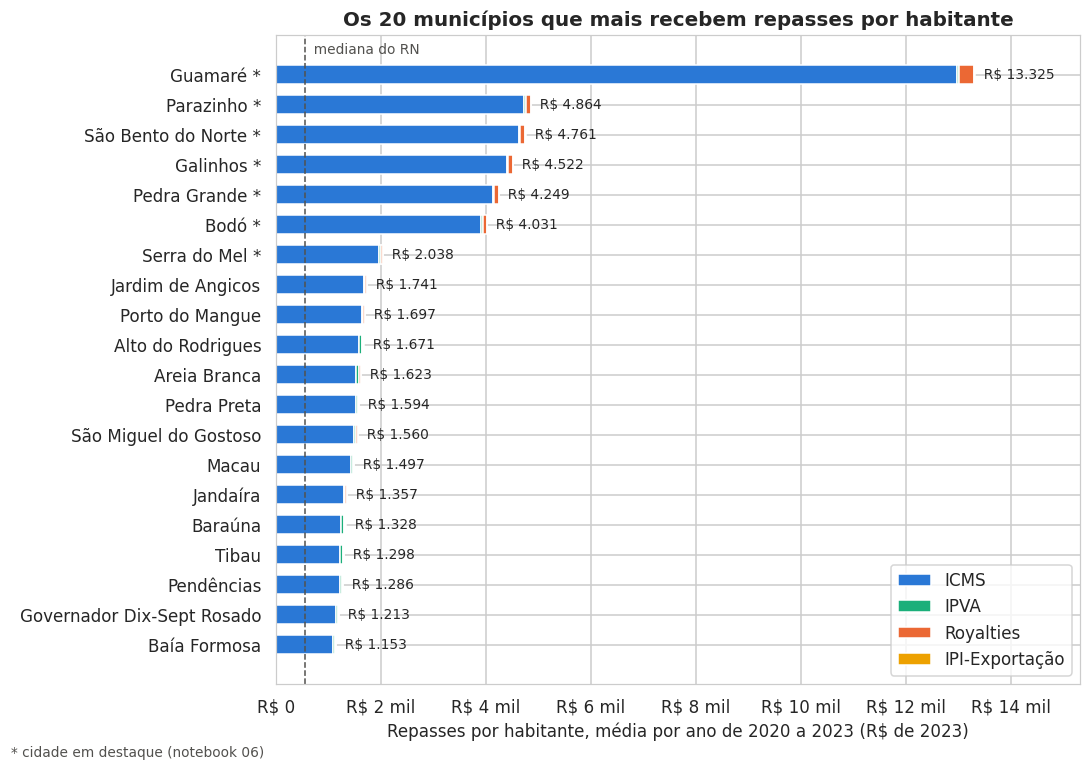

In [13]:
mun = base.groupby(['cod_ibge', 'municipio', 'mesorregiao', 'regiao_intermediaria', 'populacao', 'porte'],
                   observed=True).agg(
    pib_per_capita=('pib_per_capita', 'mean'),
    pct_baixa_renda=('pct_baixa_renda', 'mean'),
).reset_index()

soma_real = (repasses.pivot_table(index='cod_ibge', columns='tipo', values='valor_real', aggfunc='sum')
             .rename(columns=lambda t: f'rep_{t.lower()}_valor'))
soma_real['rep_total_valor'] = soma_real.sum(axis=1)
mun = mun.merge(soma_real.reset_index(), on='cod_ibge')
for col in ['rep_icms_valor', 'rep_ipva_valor', 'rep_ipi_valor', 'rep_royalties_valor', 'rep_total_valor']:
    mun[col.replace('_valor', '_pc_ano')] = mun[col] / mun['populacao'] / len(ANOS)
mun['posicao_repasses'] = mun['rep_total_pc_ano'].rank(ascending=False, method='min').astype(int)

mediana = mun['rep_total_pc_ano'].median()
print(f'Mediana do RN: R$ {virgula(mediana, 0)} por habitante por ano')

top = mun.sort_values('rep_total_pc_ano', ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(top))
esquerda = np.zeros(len(top))
for tipo, cor in ORDEM_TIPOS:
    col = f'rep_{tipo.lower()}_pc_ano'
    ax.barh(y, top[col], left=esquerda, color=cor, height=0.65, label=NOMES_TIPOS[tipo], edgecolor='white', linewidth=1)
    esquerda += top[col].values
for yi, total in zip(y, top['rep_total_pc_ano']):
    ax.text(total, yi, f'  R$ {virgula(total, 0)}', va='center', fontsize=9)
ax.axvline(mediana, color=TEXTO_2, linestyle='--', linewidth=1)
ax.text(mediana, len(top) - 0.3, '  mediana do RN', fontsize=9, color=TEXTO_2)
ax.set_yticks(y)
ax.set_yticklabels([f'{m} *' if m in CIDADES_DESTAQUE else m for m in top['municipio']])
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, top['rep_total_pc_ano'].max() * 1.15)
ax.set_xlabel('Repasses por habitante, média por ano de 2020 a 2023 (R$ de 2023)')
ax.set_title('Os 20 municípios que mais recebem repasses por habitante')
ax.legend(loc='lower right')
fig.text(0.01, 0.005, '* cidade em destaque (notebook 06)', fontsize=9, color=TEXTO_2)
plt.tight_layout()
plt.show()

### 8.3 E as cidades em destaque?

In [14]:
(mun.loc[mun['municipio'].isin(CIDADES_DESTAQUE)]
 .set_index('municipio')[['populacao', 'rep_icms_pc_ano', 'rep_royalties_pc_ano', 'rep_total_pc_ano', 'posicao_repasses']]
 .sort_values('posicao_repasses')
 .assign(**{'Quantas vezes a mediana': lambda d: d['rep_total_pc_ano'] / mediana})
 .rename(columns={'populacao': 'População', 'rep_icms_pc_ano': 'ICMS (R$/hab/ano)',
                  'rep_royalties_pc_ano': 'Royalties (R$/hab/ano)', 'rep_total_pc_ano': 'Total (R$/hab/ano)',
                  'posicao_repasses': 'Posição no RN (de 167)'}))

,População,ICMS (R$/hab/ano),Royalties (R$/hab/ano),Total (R$/hab/ano),Posição no RN (de 167),Quantas vezes a mediana
municipio,,,,,,
Guamaré,15295,"12,972.8",295.3,"13,325.2",1,24.3
Parazinho,4801,"4,736.8",99.1,"4,864.2",2,8.9
São Bento do Norte,3304,"4,638.7",95.0,"4,761.2",3,8.7
Galinhos,2104,"4,396.1",92.2,"4,521.6",4,8.3
Pedra Grande,3618,"4,137.1",79.5,"4,248.6",5,7.8
Bodó,2306,"3,915.8",85.3,"4,030.9",6,7.4
Serra do Mel,13091,"1,958.6",35.5,"2,037.8",7,3.7


## 9. Arquivos finais

No Colab, os arquivos ficam na pasta `resultado_final/saida/` do painel de arquivos (ícone de pasta à esquerda): baixe e
suba para a pasta `resultado_final/saida/` do repositório.

In [15]:
longo = (repasses.merge(municipios[['cod_ibge', 'municipio']], on='cod_ibge')
         .rename(columns={'valor': 'valor_nominal'})
         [['cod_ibge', 'municipio', 'ano', 'tipo', 'valor_nominal', 'fator_ipca', 'valor_real']]
         .sort_values(['cod_ibge', 'ano', 'tipo']))
longo.to_csv('resultado_final/saida/01_repasses_municipio_ano.csv', index=False)

final = mun[['cod_ibge', 'municipio', 'mesorregiao', 'regiao_intermediaria', 'populacao', 'porte',
             'rep_icms_valor', 'rep_ipva_valor', 'rep_ipi_valor', 'rep_royalties_valor', 'rep_total_valor',
             'rep_icms_pc_ano', 'rep_ipva_pc_ano', 'rep_ipi_pc_ano', 'rep_royalties_pc_ano', 'rep_total_pc_ano',
             'posicao_repasses', 'pib_per_capita', 'pct_baixa_renda']].sort_values('cod_ibge')
final.to_csv('resultado_final/saida/01_repasses_municipios_2020_2023.csv', index=False)

base.to_csv('resultado_final/saida/01_base_municipios_2020_2023.csv', index=False)

# Conferência: os três arquivos têm o mesmo total
total_real = base['rep_total_real'].sum()
assert abs(longo['valor_real'].sum() - total_real) < 1
assert abs(final['rep_total_valor'].sum() - total_real) < 1
assert len(final) == 167
print(f'01_repasses_municipio_ano.csv: {len(longo):,} linhas | 01_repasses_municipios_2020_2023.csv: {len(final)} '
      f'municípios | 01_base_municipios_2020_2023.csv: {len(base)} linhas'.replace(',', '.'))
print(f'Total de 2020 a 2023: {reais(total_real)} (R$ de 2023)')
final.head()

01_repasses_municipio_ano.csv: 2.672 linhas | 01_repasses_municipios_2020_2023.csv: 167 municípios | 01_base_municipios_2020_2023.csv: 668 linhas
Total de 2020 a 2023: R$ 8,84 bi (R$ de 2023)


,cod_ibge,municipio,mesorregiao,regiao_intermediaria,populacao,porte,rep_icms_valor,rep_ipva_valor,rep_ipi_valor,rep_royalties_valor,rep_total_valor,rep_icms_pc_ano,rep_ipva_pc_ano,rep_ipi_pc_ano,rep_royalties_pc_ano,rep_total_pc_ano,posicao_repasses,pib_per_capita,pct_baixa_renda
0,2400109,Acari,Central Potiguar,Caicó,10597,10–20 mil,"17,062,621.0","2,060,993.5","23,191.4","359,562.4","19,506,368.4",402.5,48.6,0.5,8.5,460.2,105,"16,597.0",53.3
1,2400208,Assú,Oeste Potiguar,Mossoró,56496,mais de 50 mil,"126,386,650.8","11,559,386.5","169,924.5","2,626,554.2","140,742,515.9",559.3,51.2,0.8,11.6,622.8,64,"33,364.6",58.1
2,2400307,Afonso Bezerra,Central Potiguar,Mossoró,10839,10–20 mil,"16,056,609.9","598,302.7","21,749.0","334,013.4","17,010,675.0",370.3,13.8,0.5,7.7,392.3,130,"15,982.8",66.9
3,2400406,Água Nova,Oeste Potiguar,Mossoró,2946,até 5 mil,"8,191,382.5","426,945.2","11,117.0","173,637.9","8,803,082.6",695.1,36.2,0.9,14.7,747.0,45,"13,856.3",70.6
4,2400505,Alexandria,Oeste Potiguar,Mossoró,13640,10–20 mil,"14,842,842.3","2,987,724.8","20,105.7","312,293.4","18,162,966.3",272.0,54.8,0.4,5.7,332.9,145,"13,976.0",57.8


### Dicionário de dados

**`01_repasses_municipios_2020_2023.csv`** (uma linha por município; valores somados de 2020 a 2023, em R\$ de 2023):

| Coluna | O que é |
|---|---|
| `cod_ibge`, `municipio` | Código IBGE (7 dígitos) e nome oficial do município |
| `mesorregiao`, `regiao_intermediaria`, `porte` | Região do IBGE e faixa de população |
| `populacao` | População do Censo 2022 |
| `rep_icms_valor`, `rep_ipva_valor`, `rep_ipi_valor`, `rep_royalties_valor` | Soma de cada repasse |
| `rep_total_valor` | Soma dos 4 repasses |
| `*_pc_ano` | O valor dividido pela população e por 4 anos: **R\$ por habitante por ano** |
| `posicao_repasses` | Posição do município no total por habitante (1 = quem mais recebe) |
| `pib_per_capita` | PIB por habitante, média de 2020 a 2023 (R\$ de 2023) |
| `pct_baixa_renda` | Pessoas de baixa renda no CadÚnico em % da população, média de 2020 a 2023 |

**`01_repasses_municipio_ano.csv`** (uma linha por município, ano e tipo de repasse):

| Coluna | O que é |
|---|---|
| `tipo` | ICMS, IPVA, IPI ou ROYALTIES |
| `valor_nominal` | Valor repassado no ano, sem correção |
| `fator_ipca` | Fator que leva o valor do ano para R\$ de 2023 |
| `valor_real` | `valor_nominal` × `fator_ipca` |

In [16]:
dicionario_base = pd.DataFrame([
    ['cod_ibge', 'Código IBGE do município (chave de integração)', 'IBGE', '-'],
    ['municipio', 'Nome oficial do município', 'IBGE', '-'],
    ['mesorregiao', 'Mesorregião (Oeste, Central, Agreste, Leste Potiguar)', 'IBGE', '-'],
    ['regiao_intermediaria', 'Região intermediária (Natal, Mossoró, Caicó, Pau dos Ferros)', 'IBGE', '-'],
    ['ano', 'Ano de referência (2020 a 2023)', '-', 'ano'],
    ['rep_icms', 'Cota-parte do ICMS recebida no ano', 'SEFAZ/RN', 'R$ nominais'],
    ['rep_ipi', 'Cota-parte do IPI-Exportação recebida no ano', 'SEFAZ/RN', 'R$ nominais'],
    ['rep_ipva', 'Cota-parte do IPVA recebida no ano', 'SEFAZ/RN', 'R$ nominais'],
    ['rep_royalties', 'Royalties do petróleo repassados no ano', 'SEFAZ/RN', 'R$ nominais'],
    ['rep_total', 'Soma dos 4 repasses', 'Derivada', 'R$ nominais'],
    ['populacao', 'População residente, Censo 2022 (fixa para todos os anos)', 'IBGE (SIDRA 4709)', 'pessoas'],
    ['pib_mil_reais', 'PIB a preços correntes', 'IBGE (SIDRA 5938)', 'R$ mil nominais'],
    ['fator_ipca', 'Fator que converte R$ do ano para R$ de 2023 (média anual do IPCA)', 'IBGE (SIDRA 1737)', 'razão'],
    ['cad_familias', 'Famílias inscritas no CadÚnico, dezembro', 'MDS', 'famílias'],
    ['cad_pessoas', 'Pessoas inscritas no CadÚnico, dezembro', 'MDS', 'pessoas'],
    ['cad_baixa_renda', 'Pessoas no CadÚnico com renda de até ½ salário mínimo por pessoa, dezembro', 'MDS', 'pessoas'],
    ['rep_total_real', 'Repasse total corrigido pelo IPCA', 'Derivada', 'R$ de 2023'],
    ['pib_real_mil', 'PIB corrigido pelo IPCA', 'Derivada', 'R$ mil de 2023'],
    ['rep_per_capita', 'Repasse total real por habitante no ano', 'Derivada', 'R$ de 2023/hab'],
    ['pib_per_capita', 'PIB real por habitante', 'Derivada', 'R$ de 2023/hab'],
    ['pct_baixa_renda', 'Pessoas de baixa renda no CadÚnico em % da população', 'Derivada', '%'],
    ['porte', 'Faixa de população (Censo 2022)', 'Derivada', 'categoria'],
], columns=['variável', 'descrição', 'fonte', 'unidade'])
assert set(dicionario_base['variável']) == set(base.columns), 'dicionário e base com colunas diferentes'
print('Dicionário do 01_base_municipios_2020_2023.csv (uma linha por município e ano):')
dicionario_base

Dicionário do 01_base_municipios_2020_2023.csv (uma linha por município e ano):


,variável,descrição,fonte,unidade
0,cod_ibge,Código IBGE do município (chave de integração),IBGE,-
1,municipio,Nome oficial do município,IBGE,-
2,mesorregiao,"Mesorregião (Oeste, Central, Agreste, Leste Po...",IBGE,-
3,regiao_intermediaria,"Região intermediária (Natal, Mossoró, Caicó, P...",IBGE,-
4,ano,Ano de referência (2020 a 2023),-,ano
5,rep_icms,Cota-parte do ICMS recebida no ano,SEFAZ/RN,R$ nominais
6,rep_ipi,Cota-parte do IPI-Exportação recebida no ano,SEFAZ/RN,R$ nominais
7,rep_ipva,Cota-parte do IPVA recebida no ano,SEFAZ/RN,R$ nominais
8,rep_royalties,Royalties do petróleo repassados no ano,SEFAZ/RN,R$ nominais
9,rep_total,Soma dos 4 repasses,Derivada,R$ nominais


## 10. Conclusões e cuidados

- **Base completa:** os 167 municípios nos 4 anos (668 linhas), sem dados faltando.
- **O ICMS é quase tudo:** cerca de 86% dos repasses de 2020 a 2023. IPVA vem em seguida; royalties e IPI-Exportação
  são pequenos no total, mas pesam muito em poucos municípios.
- **Quem mais recebe por habitante** são municípios pequenos com muita atividade econômica (parques eólicos e solares,
  petróleo, sal), e não os mais pobres. Faz sentido: a regra do ICMS distribui principalmente pelo valor adicionado,
  ou seja, pela produção que acontece no município.
- **Cuidados:**
  - os repasses do arquivo `01_base_municipios_2020_2023.csv` estão **sem correção** (colunas `rep_*`); para comparar
    anos ou fontes, use `rep_total_real` ou multiplique por `fator_ipca`. Nos outros dois arquivos, os valores já estão
    em R\$ de 2023;
  - alguns municípios têm mais pessoas no CadÚnico do que habitantes (cadastro desatualizado). O `pct_baixa_renda`
    desses municípios deve ser lido com cuidado;
  - o FUNDEB não está nesta base: ele não é um repasse da SEFAZ, e sim um fundo da educação (aparece no SICONFI,
    usado no notebook 06 da raiz).

**Próximo passo (notebook 04, junção das bases):** juntar `resultado_final/saida/01_repasses_municipios_2020_2023.csv`
com os convênios (notebook 02) e as emendas (notebook 03).